# 01 · Exploratory Data Analysis

Exploratory data analysis on the TRAIN and STUDENT-TEST partitions.
(The evaluator-test partition is never read here.)

Outputs:
  results/eda_inventory.csv         per-trip inventory and quality stats
  results/eda_summary.csv           partition-level summary
  figures/eda_*.png                 plots
  maps/eda_trip_<id>.html           Folium map: GPS, road network, reference route

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent          # run this notebook from the notebooks/ folder
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import folium

from pathsnap import config as C
from pathsnap.data_io import load_trip, list_trips
from pathsnap.labels import align_points_to_route

In [2]:
C.FIGURES.mkdir(exist_ok=True); C.MAPS.mkdir(exist_ok=True); C.RESULTS.mkdir(exist_ok=True)

In [3]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(a))

In [4]:
def trip_stats(split, d):
    tid = d.name
    raw = np.loadtxt(d / f"{tid}.track", ndmin=2)
    trip = load_trip(d)
    T = trip.track
    dt = np.diff(T[:, 2])
    step = haversine(T[:-1, 0], T[:-1, 1], T[1:, 0], T[1:, 1])
    G = nx.DiGraph(); G.add_nodes_from(range(len(trip.nodes))); G.add_edges_from(map(tuple, trip.arcs))
    deg = np.array([G.degree(n) for n in G.nodes])
    wcc = list(nx.weakly_connected_components(G))
    scc_sizes = sorted((len(c) for c in nx.strongly_connected_components(G)), reverse=True)
    rt = trip.route
    contig = float((trip.arcs[rt[:-1], 1] == trip.arcs[rt[1:], 0]).mean()) if len(rt) > 1 else 1.0
    _, _, lab_d = align_points_to_route(trip)
    return dict(
        split=split, trip=tid,
        n_gps=len(raw), n_nan=int((~np.isfinite(raw)).any(axis=1).sum()),
        n_dup_or_unsorted=int(len(raw) - len(T)),
        n_nodes=len(trip.nodes), n_arcs=len(trip.arcs), n_route_arcs=len(rt),
        duration_s=float(T[-1, 2] - T[0, 2]),
        dt_median=float(np.median(dt)), pct_dt_1s=float((dt == 1).mean()),
        n_gaps_gt10s=int((dt > 10).sum()), max_gap_s=float(dt.max()),
        path_len_km=float(step.sum() / 1000), max_jump_m=float(step.max()),
        lon_min=T[:, 0].min(), lon_max=T[:, 0].max(), lat_min=T[:, 1].min(), lat_max=T[:, 1].max(),
        lon_c=trip.lon0, lat_c=trip.lat0,
        isolated_nodes=int((deg == 0).sum()), n_weak_components=len(wcc),
        largest_scc_frac=scc_sizes[0] / len(trip.nodes),
        two_way_arc_frac=float(np.mean([G.has_edge(b, a) for a, b in trip.arcs])),
        route_contiguity=contig,
        median_gps_to_route_m=float(np.median(lab_d)),
        frac_points_labelled=float((lab_d <= C.LABEL_RELIABLE_M).mean()),
    )

In [5]:
def folium_trip(d, out):
    trip = load_trip(d)
    T = trip.track
    m = folium.Map(location=[trip.lat0, trip.lon0], zoom_start=14, tiles="OpenStreetMap")
    net = folium.FeatureGroup(name="Road network (arcs)", show=True)
    lat_pad, lon_pad = 0.003, 0.005
    box = ((trip.nodes[:, 0] > T[:, 0].min() - lon_pad) & (trip.nodes[:, 0] < T[:, 0].max() + lon_pad) &
           (trip.nodes[:, 1] > T[:, 1].min() - lat_pad) & (trip.nodes[:, 1] < T[:, 1].max() + lat_pad))
    for a, b in trip.arcs:
        if box[a] and box[b] and a < b:
            folium.PolyLine([(trip.nodes[a, 1], trip.nodes[a, 0]), (trip.nodes[b, 1], trip.nodes[b, 0])],
                            color="#9e9e9e", weight=1, opacity=0.6).add_to(net)
    net.add_to(m)
    ref = folium.FeatureGroup(name="Reference route", show=True)
    for a in trip.route:
        f, t = trip.arcs[a]
        folium.PolyLine([(trip.nodes[f, 1], trip.nodes[f, 0]), (trip.nodes[t, 1], trip.nodes[t, 0])],
                        color="#2e7d32", weight=5, opacity=0.8).add_to(ref)
    ref.add_to(m)
    gps = folium.FeatureGroup(name="Raw GPS observations", show=True)
    stride = max(1, len(T) // 1500)
    for lon, lat, t in T[::stride]:
        folium.CircleMarker((lat, lon), radius=2, color="#1565c0", fill=True, fill_opacity=0.8,
                            popup=f"t={t:.0f}s").add_to(gps)
    gps.add_to(m)
    folium.Marker((T[0, 1], T[0, 0]), tooltip="Start", icon=folium.Icon(color="green")).add_to(m)
    folium.Marker((T[-1, 1], T[-1, 0]), tooltip="End", icon=folium.Icon(color="red")).add_to(m)
    legend = f"""<div style="position: fixed; bottom: 30px; left: 30px; z-index:9999; background:white;
      padding:10px 12px; border-radius:6px; font-size:13px; box-shadow:0 1px 4px rgba(0,0,0,.3)">
      <b>Trip {trip.trip_id}</b><br>
      <span style="color:#1565c0">&#9679;</span> Raw GPS<br>
      <span style="color:#2e7d32">&#9644;</span> Reference route<br>
      <span style="color:#9e9e9e">&#9644;</span> Road network</div>"""
    m.get_root().html.add_child(folium.Element(legend))
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[T[:, 1].min(), T[:, 0].min()], [T[:, 1].max(), T[:, 0].max()]])
    m.save(str(out))

In [6]:
rows = []
for split, sd in [("train", C.TRAIN_DIR), ("student_test", C.STUDENT_TEST_DIR)]:
    for d in list_trips(sd):
        rows.append(trip_stats(split, d))
inv = pd.DataFrame(rows)
inv.to_csv(C.RESULTS / "eda_inventory.csv", index=False)
summ = inv.groupby("split").agg(
    trips=("trip", "count"), gps_total=("n_gps", "sum"), gps_median=("n_gps", "median"),
    gps_min=("n_gps", "min"), gps_max=("n_gps", "max"), nan_rows=("n_nan", "sum"),
    pct_dt_1s=("pct_dt_1s", "mean"), trips_with_gap_gt60s=("max_gap_s", lambda s: int((s > 60).sum())),
    arcs_median=("n_arcs", "median"), route_arcs_median=("n_route_arcs", "median"),
    isolated_nodes_total=("isolated_nodes", "sum"), two_way_frac=("two_way_arc_frac", "mean"),
    frac_points_labelled=("frac_points_labelled", "mean"))
summ.to_csv(C.RESULTS / "eda_summary.csv")
print(summ.T)

split                 student_test          train
trips                    10.000000      80.000000
gps_total             19160.000000  208417.000000
gps_median             1420.000000    1529.000000
gps_min                 262.000000     361.000000
gps_max                3958.000000   19313.000000
nan_rows                  0.000000       0.000000
pct_dt_1s                 0.981990       0.938296
trips_with_gap_gt60s      1.000000      22.000000
arcs_median           13145.000000   19526.500000
route_arcs_median       250.000000     280.000000
isolated_nodes_total      0.000000       0.000000
two_way_frac              0.926940       0.921673
frac_points_labelled      0.999318       0.975209


### plots

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for s, c in [("train", "#1565c0"), ("student_test", "#ef6c00")]:
    x = inv[inv.split == s]
    ax[0].hist(np.log10(x.n_gps), bins=20, alpha=.6, color=c, label=s)
    ax[1].hist(np.log10(x.n_arcs), bins=20, alpha=.6, color=c, label=s)
    ax[2].hist(x.median_gps_to_route_m, bins=20, alpha=.6, color=c, label=s)
ax[0].set_xlabel("log10(GPS points per trip)"); ax[1].set_xlabel("log10(arcs per trip)")
ax[2].set_xlabel("median GPS-to-reference-arc distance (m)")
for a in ax: a.legend(); a.set_ylabel("trips")
fig.suptitle("Trip size and GPS noise (train + student_test)"); fig.tight_layout()
fig.savefig(C.FIGURES / "eda_trip_sizes.png", dpi=130); plt.close(fig)

### sampling interval distribution (train)

In [8]:
dts = []
for d in list_trips(C.TRAIN_DIR):
    T = load_trip(d).track; dts.append(np.diff(T[:, 2]))
dts = np.concatenate(dts)
fig, ax = plt.subplots(figsize=(7, 4))
vals, cnts = np.unique(np.clip(dts, 0, 11), return_counts=True)
ax.bar([str(int(v)) if v < 11 else ">10" for v in vals], cnts / cnts.sum(), color="#1565c0")
ax.set_yscale("log"); ax.set_xlabel("time between consecutive GPS points (s)"); ax.set_ylabel("fraction (log)")
ax.set_title(f"Sampling intervals, train partition (n={len(dts):,}); 1 s = {np.mean(dts==1):.1%}")
fig.tight_layout(); fig.savefig(C.FIGURES / "eda_sampling_intervals.png", dpi=130); plt.close(fig)

### geographic spread of trips

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
for s, c in [("train", "#1565c0"), ("student_test", "#ef6c00")]:
    x = inv[inv.split == s]; ax.scatter(x.lon_c, x.lat_c, s=25, c=c, label=s)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.grid(alpha=.3)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend()
ax.set_title("Trip locations (centroids): data spans many countries"); fig.tight_layout()
fig.savefig(C.FIGURES / "eda_trip_locations.png", dpi=130); plt.close(fig)

### label coverage per trip

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
x = inv.sort_values("frac_points_labelled")
ax.bar(range(len(x)), x.frac_points_labelled, color=np.where(x.split == "train", "#1565c0", "#ef6c00"))
ax.set_ylabel("fraction of GPS points\nwithin 50 m of aligned route arc"); ax.set_xlabel("trips (sorted)")
ax.set_title("Reference-route coverage of the GPS track (blue=train, orange=student_test)")
fig.tight_layout(); fig.savefig(C.FIGURES / "eda_label_coverage.png", dpi=130); plt.close(fig)

### one trajectory over its road network (static view of a Folium map)

In [11]:
for tid, split_dir in [("00000048", C.TRAIN_DIR), ("00000040", C.STUDENT_TEST_DIR)]:
    trip = load_trip(split_dir / tid)
    T = trip.track
    fig, ax = plt.subplots(figsize=(7, 7))
    pad = 0.004
    box = ((trip.nodes[:, 0] > T[:, 0].min() - pad) & (trip.nodes[:, 0] < T[:, 0].max() + pad) &
           (trip.nodes[:, 1] > T[:, 1].min() - pad) & (trip.nodes[:, 1] < T[:, 1].max() + pad))
    for a, b in trip.arcs:
        if box[a] and box[b]:
            ax.plot(trip.nodes[[a, b], 0], trip.nodes[[a, b], 1], color="#bdbdbd", lw=.6, zorder=1)
    for a in trip.route:
        ax.plot(trip.nodes[trip.arcs[a], 0], trip.nodes[trip.arcs[a], 1], color="#2e7d32", lw=3, zorder=2)
    ax.scatter(T[:, 0], T[:, 1], s=3, c="#1565c0", zorder=3)
    ax.plot([], [], color="#bdbdbd", label="road network"); ax.plot([], [], color="#2e7d32", lw=3, label="reference route")
    ax.scatter([], [], c="#1565c0", s=8, label="GPS")
    ax.legend(loc="upper left"); ax.set_aspect(1 / np.cos(np.radians(trip.lat0)))
    ax.set_title(f"Trip {tid}: GPS over road network"); fig.tight_layout()
    fig.savefig(C.FIGURES / f"eda_trip_{tid}.png", dpi=130); plt.close(fig)
    folium_trip(split_dir / tid, C.MAPS / f"eda_trip_{tid}.html")
print("EDA done")

EDA done


### Saved figures

eda_label_coverage.png


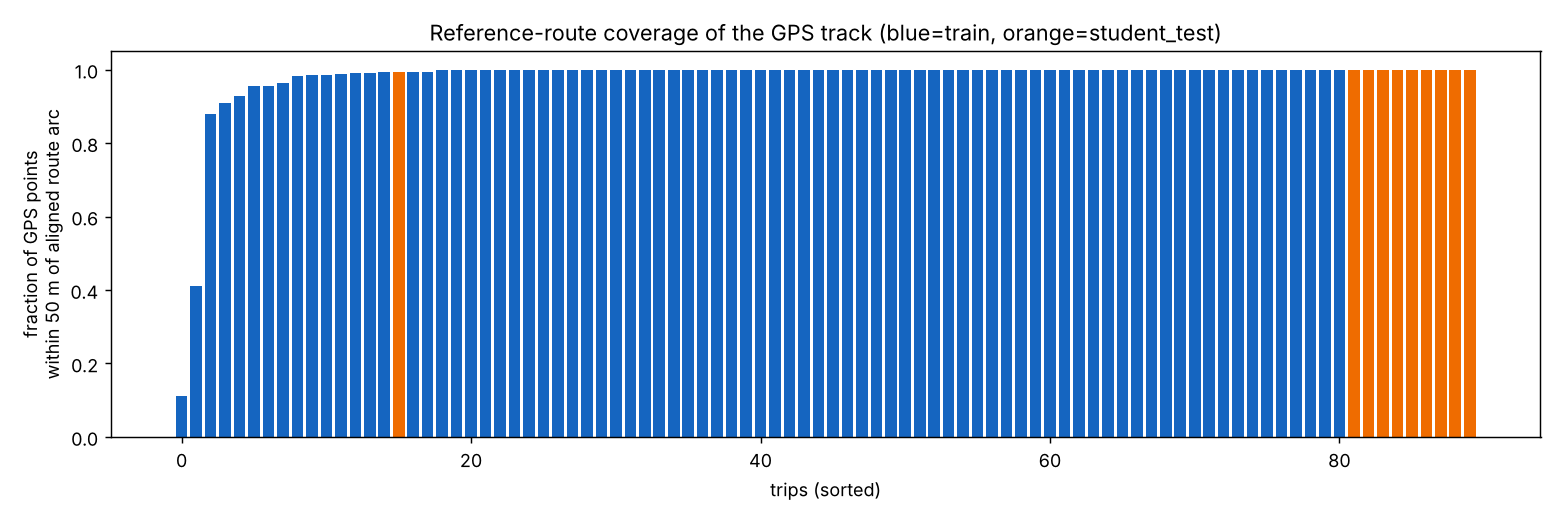

eda_sampling_intervals.png


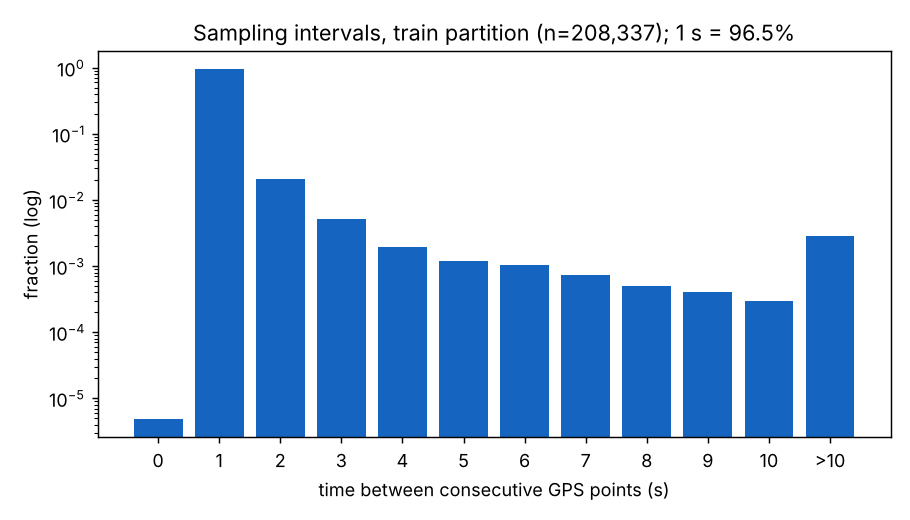

eda_trip_00000040.png


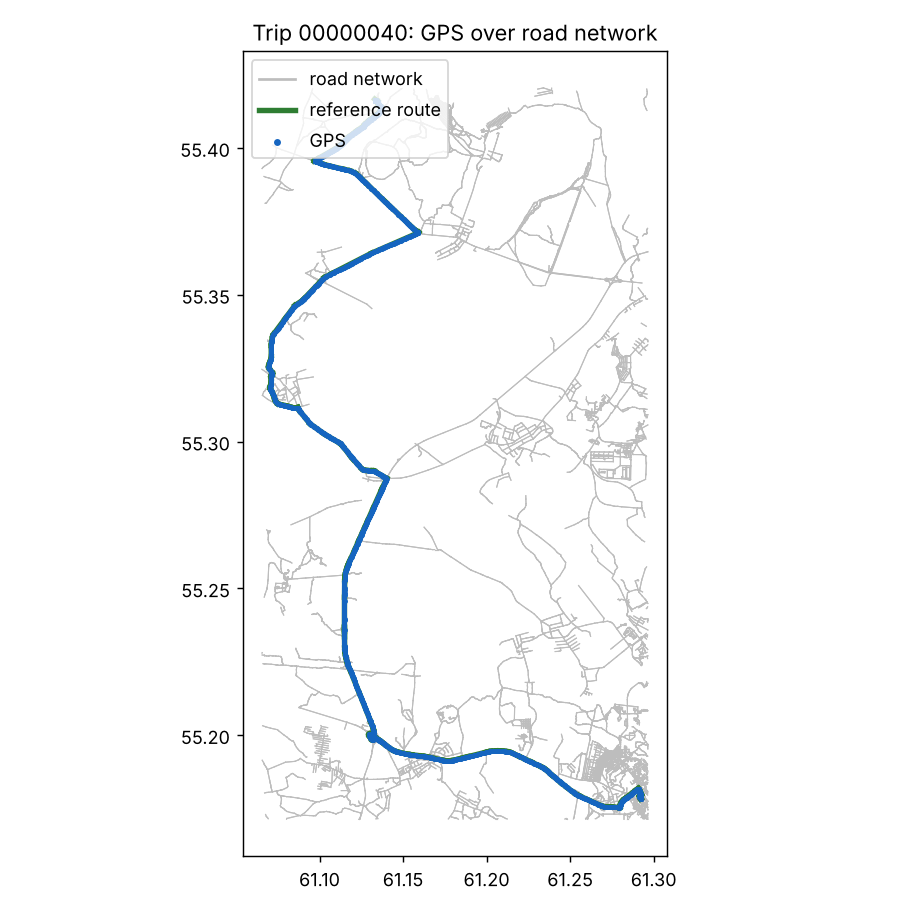

eda_trip_00000048.png


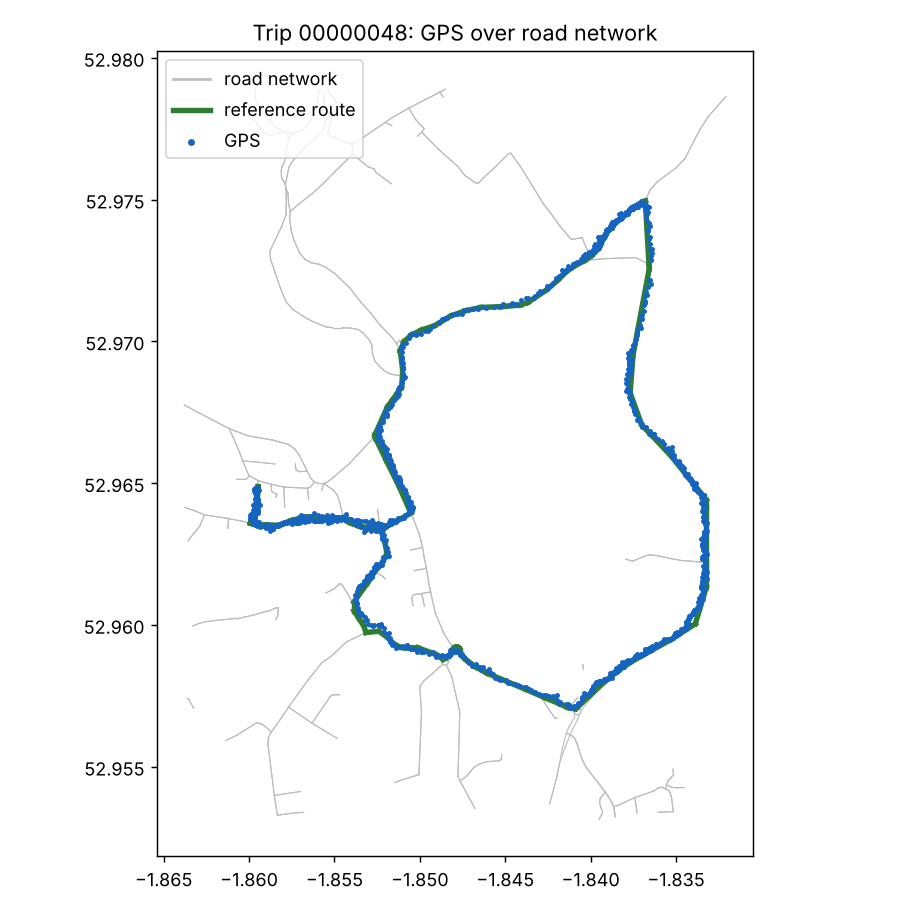

eda_trip_locations.png


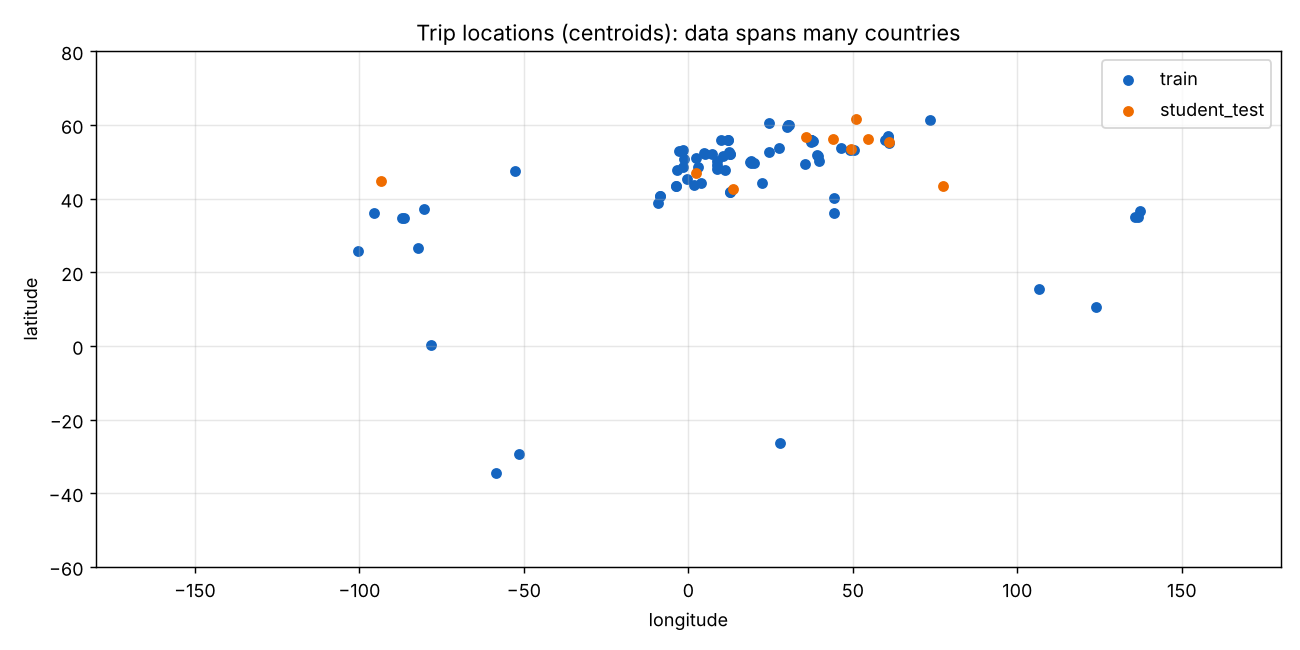

eda_trip_sizes.png


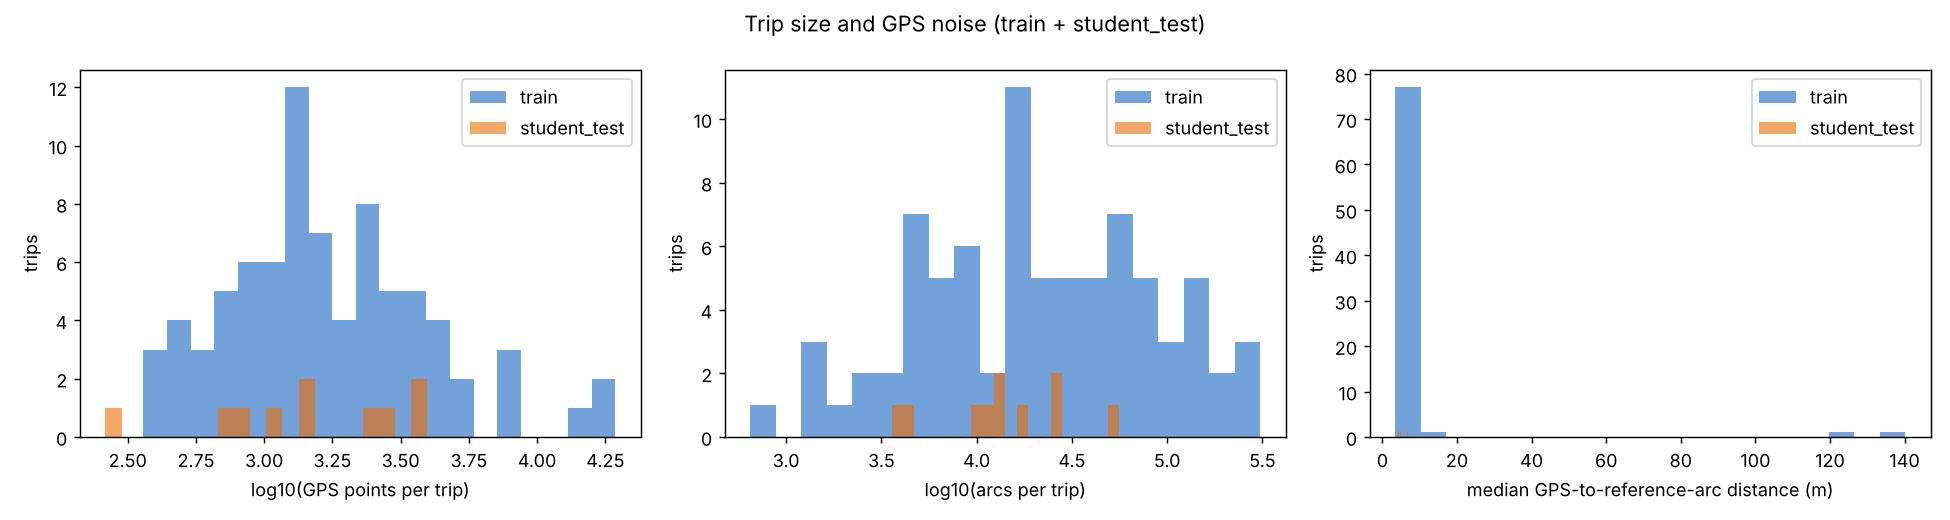

In [12]:
from IPython.display import Image, display
for f in sorted(C.FIGURES.glob("eda_*.png")):
    print(f.name); display(Image(str(f), width=800))